#  machine learning
**السؤال:** هل نقدر نتوقع إن العميل هيدي تقييم سيئ؟


## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             f1_score, roc_auc_score, roc_curve)

df = pd.read_csv('data/preprocessed.csv')
print(df.shape)
df.head()

(112650, 17)


,order_id,order_item_id,product_id,order_status,product_category,product_name_lenght,product_description_lenght,product_photos_qty,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,price,freight_value,review_score,review_creation_date,review_comment_title,review_comment_message
0,e481f51cbdc54678b7cc49136f2d6af7,1,87285b34884572647811a353c7ac498a,delivered,housewares,40.0,268.0,4.0,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,29.99,8.72,4.0,2017-10-11 00:00:00,NaN,"Não testei o produto ainda, mas ele veio corre..."
1,53cdb2fc8bc7dce0b6741e2150273451,1,595fac2a385ac33a80bd5114aec74eb8,delivered,perfumery,29.0,178.0,1.0,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,118.70,22.76,4.0,2018-08-08 00:00:00,Muito boa a loja,Muito bom o produto.
2,47770eb9100c2d0c44946d9cf07ec65d,1,aa4383b373c6aca5d8797843e5594415,delivered,auto,46.0,232.0,1.0,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,159.90,19.22,5.0,2018-08-18 00:00:00,NaN,NaN
3,949d5b44dbf5de918fe9c16f97b45f8a,1,d0b61bfb1de832b15ba9d266ca96e5b0,delivered,pet_shop,59.0,468.0,3.0,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15 00:00:00,45.00,27.20,5.0,2017-12-03 00:00:00,NaN,O produto foi exatamente o que eu esperava e e...
4,ad21c59c0840e6cb83a9ceb5573f8159,1,65266b2da20d04dbe00c5c2d3bb7859e,delivered,stationery,38.0,316.0,4.0,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26 00:00:00,19.90,8.72,5.0,2018-02-17 00:00:00,NaN,NaN


## 2. Preprocessing


In [ ]:
for c in ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']:
    df[c] = pd.to_datetime(df[c])

df = df[(df['order_status'] == 'delivered') & df['order_delivered_customer_date'].notna() & df['review_score'].notna()].copy()

df['delivery_days'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.total_seconds() / 86400
df['delivery_delay_days'] = (df['order_delivered_customer_date'] - df['order_estimated_delivery_date']).dt.total_seconds() / 86400
df['purchase_month'] = df['order_purchase_timestamp'].dt.month
df['purchase_day_of_week'] = df['order_purchase_timestamp'].dt.dayofweek


df['bad_review'] = (df['review_score'] <= 3).astype(int)
print(df.shape)
print(df['bad_review'].value_counts())
print('نسبة التقييم السيئ:', round(df['bad_review'].mean(), 3))

(109362, 22)
bad_review
0    84019
1    25343
Name: count, dtype: int64
نسبة التقييم السيئ: 0.232


In [ ]:

num_cols = ['price', 'freight_value', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty',
            'order_item_id', 'delivery_days', 'delivery_delay_days', 'purchase_month', 'purchase_day_of_week']
print(df[num_cols].isnull().sum())
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

price                            0
freight_value                    0
product_name_lenght           1525
product_description_lenght    1525
product_photos_qty            1525
order_item_id                    0
delivery_days                    0
delivery_delay_days              0
purchase_month                   0
purchase_day_of_week             0
dtype: int64


In [ ]:

df['product_category'] = df['product_category'].fillna('unknown')
top10 = df['product_category'].value_counts().head(10).index
df['category_group'] = df['product_category'].where(df['product_category'].isin(top10), 'other')

X = pd.get_dummies(df[num_cols + ['category_group']], columns=['category_group'], drop_first=True)
y = df['bad_review']
print(X.shape)

(109362, 20)


## 3. Split: Train / Validation / Test


In [5]:
orders = df.groupby('order_id')['bad_review'].max()
tr_ids, tmp_ids = train_test_split(orders.index, test_size=0.4, random_state=42, stratify=orders)
val_ids, te_ids = train_test_split(tmp_ids, test_size=0.5, random_state=42, stratify=orders.loc[tmp_ids])

tr, va, te = df['order_id'].isin(tr_ids), df['order_id'].isin(val_ids), df['order_id'].isin(te_ids)
X_train, y_train = X[tr], y[tr]
X_val,   y_val   = X[va], y[va]
X_test,  y_test  = X[te], y[te]
print(len(X_train), len(X_val), len(X_test))
print(y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

65559 21944 21859
0.231 0.235 0.229


## 4. Feature Scaling


In [6]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

## 5. Model 1: Logistic Regression


In [ ]:
log_reg = LogisticRegression(max_iter=1000, class_weight='balanced')
log_reg.fit(X_train_s, y_train)

coef = pd.Series(log_reg.coef_[0], index=X.columns).sort_values()
coef.tail(6) 

product_name_lenght               0.044174
category_group_furniture_decor    0.054240
category_group_bed_bath_table     0.085236
delivery_delay_days               0.159775
order_item_id                     0.300371
delivery_days                     0.563630
dtype: float64

In [8]:
print('Validation F1:', round(f1_score(y_val, log_reg.predict(X_val_s)), 3))

Validation F1: 0.45


## 6. Model 2: KNN


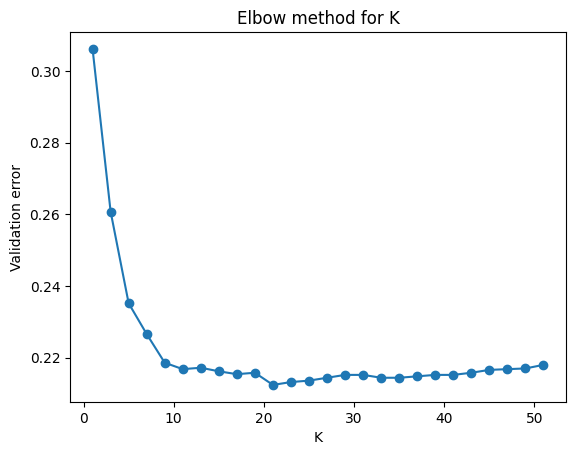

Best K = 21


In [9]:
sample = X_train_s[:10000]; y_sample = y_train.iloc[:10000]
ks = range(1, 52, 2)
errors = []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k).fit(sample, y_sample)
    errors.append(1 - knn.score(X_val_s[:5000], y_val.iloc[:5000]))

plt.plot(ks, errors, marker='o')
plt.xlabel('K'); plt.ylabel('Validation error'); plt.title('Elbow method for K')
plt.show()
best_k = list(ks)[int(np.argmin(errors))]
print('Best K =', best_k)

In [10]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_s, y_train)
print('Validation F1:', round(f1_score(y_val, knn.predict(X_val_s)), 3))

Validation F1: 0.275


## 7. Model 3: Decision Tree


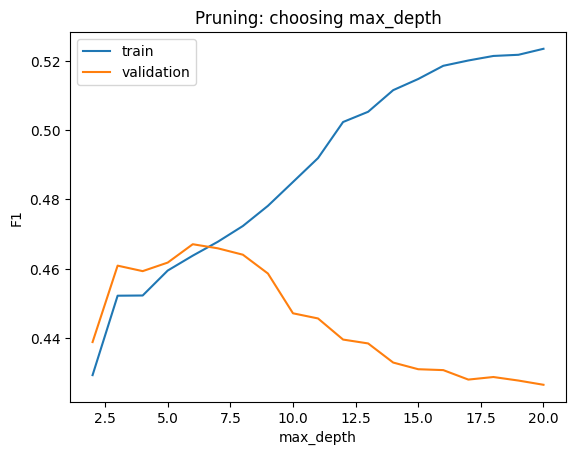

Best max_depth = 6


In [11]:
depths = range(2, 21)
train_f1, val_f1 = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, min_samples_leaf=50, class_weight='balanced', random_state=42).fit(X_train, y_train)
    train_f1.append(f1_score(y_train, t.predict(X_train)))
    val_f1.append(f1_score(y_val, t.predict(X_val)))

plt.plot(depths, train_f1, label='train'); plt.plot(depths, val_f1, label='validation')
plt.xlabel('max_depth'); plt.ylabel('F1'); plt.legend(); plt.title('Pruning: choosing max_depth')
plt.show()
best_depth = list(depths)[int(np.argmax(val_f1))]
print('Best max_depth =', best_depth)

In [12]:
tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=50, class_weight='balanced', random_state=42)
tree.fit(X_train, y_train)
print('Validation F1:', round(f1_score(y_val, tree.predict(X_val)), 3))

Validation F1: 0.467


## 8. Model 4: Random Forest


In [13]:
forest = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20,
                                class_weight='balanced', n_jobs=-1, random_state=42)
forest.fit(X_train, y_train)
print('Validation F1:', round(f1_score(y_val, forest.predict(X_val)), 3))

Validation F1: 0.468


## 9. Choosing the threshold


In [14]:
models = {
    'Logistic Regression': (log_reg, X_val_s, X_test_s),
    'KNN': (knn, X_val_s, X_test_s),
    'Decision Tree': (tree, X_val, X_test),
    'Random Forest': (forest, X_val, X_test),
}
thresholds = np.arange(0.1, 0.9, 0.02)
best_thr = {}
for name, (m, Xv, Xt) in models.items():
    p = m.predict_proba(Xv)[:, 1]
    scores = [f1_score(y_val, (p >= t).astype(int)) for t in thresholds]
    best_thr[name] = thresholds[int(np.argmax(scores))]
best_thr

{'Logistic Regression': np.float64(0.5000000000000001),
 'KNN': np.float64(0.2),
 'Decision Tree': np.float64(0.4600000000000001),
 'Random Forest': np.float64(0.4600000000000001)}

## 10. Final evaluation on the Test set

In [15]:
rows = []
probs = {}
for name, (m, Xv, Xt) in models.items():
    p = m.predict_proba(Xt)[:, 1]
    probs[name] = p
    pred = (p >= best_thr[name]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'Model': name, 'Threshold': round(best_thr[name], 2),
                 'Precision': tp / (tp + fp), 'Recall': tp / (tp + fn),
                 'F1': f1_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, p)})
results = pd.DataFrame(rows).set_index('Model').round(3)
results

,Threshold,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.50,0.366,0.519,0.429,0.670
KNN,0.20,0.328,0.562,0.414,0.652
Decision Tree,0.46,0.393,0.509,0.444,0.678
Random Forest,0.46,0.399,0.522,0.452,0.695


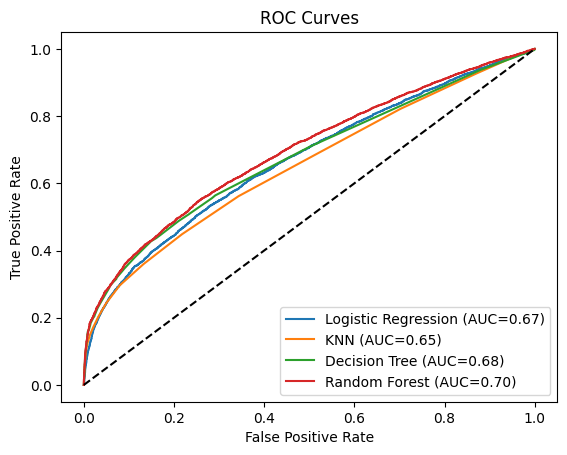

In [ ]:

for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.legend(); plt.title('ROC Curves')
plt.show()

Best model: Random Forest
              precision    recall  f1-score   support

  good (4-5)       0.84      0.77      0.80     16846
   bad (1-3)       0.40      0.52      0.45      5013

    accuracy                           0.71     21859
   macro avg       0.62      0.64      0.63     21859
weighted avg       0.74      0.71      0.72     21859



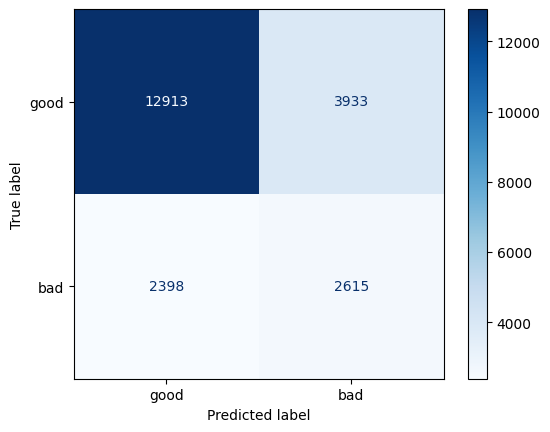

In [ ]:

best_name = results['ROC-AUC'].idxmax()
pred = (probs[best_name] >= best_thr[best_name]).astype(int)
print('Best model:', best_name)
print(classification_report(y_test, pred, target_names=['good (4-5)', 'bad (1-3)']))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['good', 'bad']).plot(cmap='Blues')
plt.show()

## 11. Which features matter? (Random Forest)

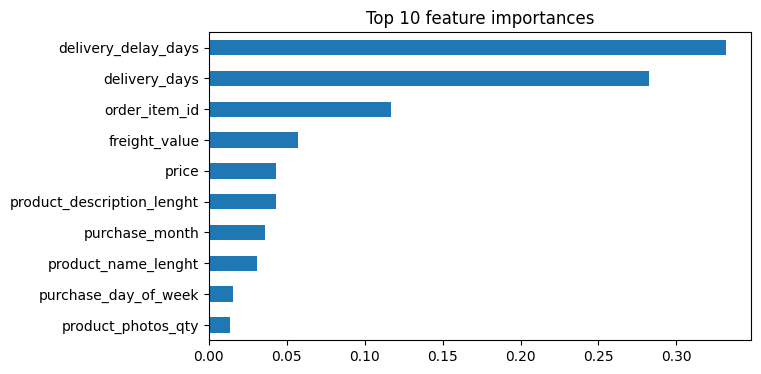

In [18]:
imp = pd.Series(forest.feature_importances_, index=X.columns).sort_values()
imp.tail(10).plot(kind='barh', figsize=(7, 4))
plt.title('Top 10 feature importances'); plt.show()

## 12. Conclusions

| Model | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Logistic Regression | 0.37 | 0.52 | 0.43 | 0.67 |
| KNN | 0.33 | 0.56 | 0.41 | 0.65 |
| Decision Tree | 0.39 | 0.51 | 0.44 | 0.68 |
| **Random Forest** | 0.39 | 0.54 | **0.45** | **0.70** |

- **أحسن موديل: Random Forest.** الأشجار عمومًا أحسن من الـ Logistic Regression و KNN هنا.
- الأداء **متوسط** (AUC حوالي 0.70، والعشوائي = 0.50). الموديل بيلقط حوالي 54% من التقييمات السيئة، لكن من كل 100 توقع "سيئ" حوالي 39 بس صح.
- **أهم عوامل التنبؤ:** `delivery_days` ثم `order_item_id` (الطلبات اللي فيها منتجات كتير) ثم `delivery_delay_days`. ده بيأكد استنتاج الـ EDA إن التوصيل أهم سبب لعدم رضا العملاء.
- التقييم السيئ ليه أسباب كتير مش موجودة في الداتا (منتج تالف، وصف مش مطابق...)، وده سبب إن الدقة مش عالية.
- **تحسينات ممكنة:** استخدام نص التعليقات (NLP)، أو إضافة بيانات البائع والمنطقة، أو تجربة Gradient Boosting.
- **مهم:** الموديل بيشتغل على الطلبات اللي اتسلمت بس، يعني بعد التوصيل.